Shahlo Solieva 

Created 08032026

RMSD to starting structure. align by framework then calculate CA RMSD.

In [1]:
import numpy as np
import mdtraj as md
import pickle
import matplotlib.pyplot as plt

# RMSD

In [2]:
def get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1]):
    # Import atom indices for FR:
    fr_indices_data_path = '/mnt/pure/bowmanlab/WG-shahlo/projects/Ab_dynamics/analysis/paratope_RMSD/data/'
    fr_indices = np.load(f'{fr_indices_data_path}{sys_name}-FR-indices-FAH.npy')
    print(fr_indices)
    
    # Import starting pdb structure
    if 'CH103_mature' in sys_name:
        cluster_dir_path = f"/mnt/pure/bowmanlab/WG-shahlo/projects/Ab_dynamics/FAH-analysis-20260212/clustering/radius_15_variable_subsample50/data/apo/{sys_name}/"
    else:    
        cluster_dir_path = f"/mnt/pure/bowmanlab/WG-shahlo/projects/Ab_dynamics/FAH-analysis-20260212/clustering/radius_15_variable_subsample50_updated/data/apo/{sys_name}/"
    print(cluster_dir_path)
    
    pdb = md.load(f'{cluster_dir_path}prot_masses_uniform.pdb')

    # Select variable region atom indices (heavy + light chains)
    start_of_VH = VH_resis[0]
    end_of_VH   = VH_resis[1]
    start_of_VL = VL_resis[0]
    end_of_VL   = VL_resis[1]
    variable_indices = np.concatenate([pdb.topology.select(f'chainid {target_chains[0]} and residue {start_of_VH} to {end_of_VH} and name CA'),
                                       pdb.topology.select(f'chainid {target_chains[1]} and residue {start_of_VL} to {end_of_VL} and name CA')])
    print(len(variable_indices), variable_indices[0:3], variable_indices[-3:])

    # Import cluster centers:
    
    #file=f"{cluster_dir_path}cluster-centers.pickle"
    if 'CAP256' in sys_name:
        file=f"{cluster_dir_path}cluster-centers-r215.pickle"
    else:
        file=f"{cluster_dir_path}cluster-centers.pickle"
    with open(file, 'rb') as file:
        centers=pickle.load(file) # load in cluster centers.

    # Import eq probabilities:
    eq_probs = np.load(f'{cluster_dir_path}eq_probs_msm_50.npy')


    print(centers[0].topology.atom(fr_indices[-1]))
    print(pdb[0].topology.atom(fr_indices[-1]))

    # RMSD, align by FR
    rmsd_values = []
    for center_ind in range(len(centers)):
        centers[center_ind].superpose(pdb, atom_indices=fr_indices)
        starting_xyz = pdb.xyz[:, variable_indices, :]
        center_xyz = centers[center_ind].xyz[0, variable_indices, :]
        rmsd = np.sqrt(np.mean(np.sum((starting_xyz - center_xyz)**2, axis=2), axis=1))
        rmsd_values.append(rmsd[0]*10) # convert nm to Angstroms
    return rmsd_values, eq_probs

In [24]:
# colors = ['#80bfff','palevioletred','pink','lavenderblush','#004080']

# PGT121

In [25]:
lineage = 'PGT121' 

sys_name = 'PGT121_naive_VC'
VH_resis = ["1","132"]
VL_resis = ["1","109"]
naive_rmsd_values, naive_eq_probs   = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1])

sys_name = 'PGT121_mature_VC'
VH_resis = ["1","132"]
VL_resis = ["1","105"]
mature_rmsd_values, mature_eq_probs = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1])

[   4   21   37   54   73   90  105  116  125  137  144  163  179  203
  215  226  241  255  274  285  304  318  328  342  358  477  501  512
  536  555  579  598  612  624  631  653  660  679  694  718  737  744
  869  883  904  920  932  943  962  984  995 1019 1035 1049 1068 1079
 1095 1107 1121 1132 1154 1168 1185 1205 1216 1235 1257 1276 1287 1298
 1314 1328 1338 1348 1360 1374 1384 1400 1421 1442 1887 1911 1918 1940
 1947 1961 1975 1991 2005 2021 2032 3650 3661 3677 3688 3704 3716 3728
 3735 3752 3766 3776 3800 3819 3833 3843 3850 3857 3955 3971 3988 4012
 4033 4050 4067 4091 4103 4110 4127 4139 4151 4167 4186 4202 4218 4274
 4286 4312 4324 4335 4342 4363 4375 4390 4414 4434 4445 4452 4463 4477
 4488 4495 4509 4523 4533 4547 4566 4580 4599 4610 4634 4650 4665 4675
 4682 4694 4709 4719 4731 4752 4773 4968 4988 4995 5002 5009 5023 5045
 5064 5078 5094]
/mnt/pure/bowmanlab/WG-shahlo/projects/Ab_dynamics/FAH-analysis-20260212/clustering/radius_15_variable_subsample50_updated/data/apo

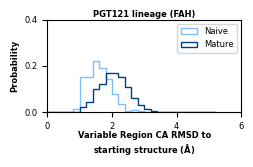

In [26]:
plt.figure(figsize=[2.5,1.2])
bins=np.arange(0,5.4,0.2)
plt.hist(naive_rmsd_values,  bins=bins,weights=naive_eq_probs,  edgecolor='#80bfff',       label='Naive', histtype='step')
plt.hist(mature_rmsd_values, bins=bins, weights=mature_eq_probs,edgecolor='#004080',       label='Mature', histtype='step')
plt.xlabel('Variable Region CA RMSD to\nstarting structure ('+r'$\mathbf{\AA}$'+')',fontsize=6, weight='bold', labelpad=0)
plt.ylabel('Probability',fontsize=6, weight='bold')
plt.title('PGT121 lineage (FAH)', fontsize=6, weight='bold', pad=2)
plt.yticks(fontsize=6)
plt.xticks(fontsize=6)
plt.legend(fontsize=6)
plt.xlim(0,6)
plt.ylim(0,0.4)
plt.savefig(f"../figures/manuscript/VH_VL_RMSD_to_starting_structure_{lineage}-FAH.pdf", dpi=300, bbox_inches='tight', transparent=True)
plt.show()

In [27]:
np.max(mature_rmsd_values)

4.679096937179565

# 1-18

In [3]:
lineage = '1-18' 

sys_name = 'Ab118_naive_VC'
VH_resis = ["1","125"]
VL_resis = ["1","108"]
naive_rmsd_values, naive_eq_probs   = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1])

sys_name = 'Ab118_mature_VC'
VH_resis = ["1","131"]
VL_resis = ["1","108"]
mature_rmsd_values, mature_eq_probs = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1])

[  21   37   54   73   89  106  117  124  134  149  165  187  211  223
  230  240  251  267  289  305  316  326  348  358  498  515  532  556
  572  596  613  625  637  644  661  668  687  702  726  743  750  866
  877  898  908  925  947  967  984  991 1015 1031 1045 1062 1076 1100
 1112 1126 1137 1151 1162 1176 1192 1213 1230 1245 1264 1275 1286 1305
 1329 1340 1355 1367 1381 1391 1407 1428 1449 1759 1783 1790 1797 1804
 1818 1828 1844 1863 1879 1890 3382 3397 3416 3432 3451 3465 3482 3495
 3507 3514 3528 3547 3558 3577 3590 3602 3609 3624 3648 3658 3672 3691
 3702 3712 3736 3746 3855 3874 3884 3908 3929 3946 3963 3987 3999 4006
 4023 4035 4047 4071 4090 4109 4128 4177 4188 4212 4222 4236 4243 4264
 4276 4288 4312 4332 4343 4350 4361 4368 4379 4386 4400 4412 4432 4446
 4465 4479 4498 4509 4533 4552 4569 4581 4596 4608 4628 4638 4654 4675
 4696 4837 4857 4864 4871 4878 4892 4914 4930 4945 4964]
/mnt/pure/bowmanlab/WG-shahlo/projects/Ab_dynamics/FAH-analysis-20260212/clustering/radius_

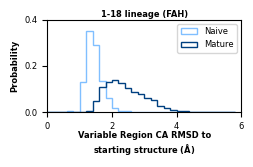

In [4]:
plt.figure(figsize=[2.5,1.2])
bins=np.arange(0,6,0.2)
plt.hist(naive_rmsd_values,  bins=bins,weights=naive_eq_probs,  edgecolor='#80bfff',       label='Naive', histtype='step')
plt.hist(mature_rmsd_values, bins=bins, weights=mature_eq_probs,edgecolor='#004080',       label='Mature', histtype='step')
plt.xlabel('Variable Region CA RMSD to\nstarting structure ('+r'$\mathbf{\AA}$'+')',fontsize=6, weight='bold', labelpad=0)
plt.ylabel('Probability',fontsize=6, weight='bold')
plt.title('1-18 lineage (FAH)', fontsize=6, weight='bold', pad=2)
plt.yticks(fontsize=6)
plt.xticks(fontsize=6)
plt.legend(fontsize=6)
plt.xlim(0,6)
plt.ylim(0,0.4)
plt.savefig(f"../figures/manuscript/VH_VL_RMSD_to_starting_structure_{lineage}-FAH.pdf", dpi=300, bbox_inches='tight', transparent=True)
plt.show()


# CAP256

In [28]:
lineage='CAP256'

sys_name = 'CAP256_naive_VC'
VH_resis = ["1","144"]
VL_resis = ["1","111"]
naive_rmsd_values, naive_eq_probs = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1])

sys_name = 'CAP256_mature_VC'
VH_resis = ["1","145"]
VL_resis = ["1","111"]
mature_rmsd_values, mature_eq_probs = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1])

[  21   37   54   73   89  104  115  122  129  136  152  168  187  199
  206  230  241  260  284  303  314  324  334  344  466  483  500  524
  540  564  581  593  605  612  634  641  660  675  699  715  725  858
  879  900  910  922  933  949  971  978 1002 1022 1036 1055 1066 1090
 1102 1116 1127 1149 1163 1177 1196 1217 1236 1253 1270 1284 1295 1314
 1338 1348 1363 1375 1389 1399 1415 1436 1457 2009 2033 2040 2057 2064
 2078 2095 2111 2125 2141 3641 3658 3669 3685 3704 3718 3737 3751 3763
 3774 3790 3801 3811 3823 3835 3842 3859 3881 3897 3911 3930 3941 3951
 3962 3969 4091 4107 4118 4142 4163 4180 4197 4218 4230 4237 4251 4263
 4275 4297 4316 4335 4354 4418 4440 4466 4478 4489 4496 4517 4529 4541
 4565 4585 4596 4603 4614 4636 4647 4654 4668 4679 4689 4703 4722 4729
 4748 4762 4769 4788 4805 4819 4826 4838 4853 4863 4875 4896 4917 5076
 5096 5103 5117 5124 5138 5160]
/mnt/pure/bowmanlab/WG-shahlo/projects/Ab_dynamics/FAH-analysis-20260212/clustering/radius_15_variable_subsample50_u

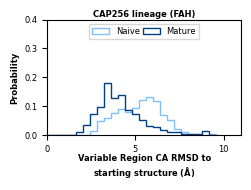

In [29]:
plt.figure(figsize=[2.5,1.5])
bins=np.arange(0,10,0.4)
plt.hist(naive_rmsd_values,  bins=bins,weights=naive_eq_probs,  edgecolor='#80bfff',       label='Naive', histtype='step')
plt.hist(mature_rmsd_values, bins=bins, weights=mature_eq_probs,edgecolor='#004080',       label='Mature', histtype='step')
plt.xlabel('Variable Region CA RMSD to\nstarting structure ('+r'$\mathbf{\AA}$'+')',fontsize=6, weight='bold', labelpad=0)
plt.ylabel('Probability',fontsize=6, weight='bold')
plt.title('CAP256 lineage (FAH)', fontsize=6, weight='bold', pad=2)
plt.yticks(fontsize=6)
plt.xticks(fontsize=6)
#plt.legend(fontsize=6, loc='center left', bbox_to_anchor=(1, 0.5))
plt.legend(fontsize=6, loc='upper center', ncols=4, columnspacing=0.4) 
plt.xlim(0,11)
plt.ylim(0,0.4)
plt.savefig(f"../figures/manuscript/VH_VL_RMSD_to_starting_structure_{lineage}-FAH.pdf", dpi=300, bbox_inches='tight', transparent=True)
plt.show()

In [30]:
print(mature_rmsd_values[0:10])
print(np.max(mature_rmsd_values))

[2.3482416570186615, 10.313299894332886, 8.659298419952393, 8.788513541221619, 5.976885557174683, 6.581239700317383, 8.028199076652527, 5.442520380020142, 4.798312187194824, 6.241967678070068]
10.46148419380188


# CH103

In [19]:
lineage='CH103'

sys_name = 'CH103_naive_VC'
VH_resis = ["1","121"]
VL_resis = ["1","108"]
naive_rmsd_values, naive_eq_probs = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1])

sys_name = 'CH103_mature_VC'
VH_resis = ["1","121"]
VL_resis = ["1","105"]
mature_rmsd_values, mature_eq_probs = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1])

[   4   21   37   54   73   90  105  116  125  137  144  163  179  203
  215  226  241  255  274  285  304  318  328  342  358  477  501  512
  536  555  579  598  612  624  631  653  660  679  694  718  737  744
  869  883  904  920  932  943  962  984  995 1019 1035 1049 1068 1079
 1095 1107 1121 1132 1154 1168 1185 1205 1216 1235 1257 1276 1287 1298
 1314 1328 1338 1348 1360 1374 1384 1400 1421 1442 1687 1711 1718 1735
 1742 1756 1775 1791 1805 1821 1832 3334 3355 3370 3389 3403 3422 3436
 3448 3459 3475 3486 3502 3515 3527 3534 3551 3565 3575 3586 3605 3619
 3629 3640 3647 3762 3772 3783 3807 3828 3845 3862 3886 3898 3905 3922
 3935 3947 3963 3982 3998 4017 4078 4100 4126 4138 4149 4156 4177 4189
 4204 4228 4248 4259 4266 4277 4291 4302 4309 4323 4337 4347 4361 4380
 4394 4413 4424 4431 4445 4462 4472 4489 4501 4516 4526 4538 4559 4580
 4745 4765 4772 4786 4793 4807 4829 4845 4859 4875]
/mnt/pure/bowmanlab/WG-shahlo/projects/Ab_dynamics/FAH-analysis-20260212/clustering/radius_15_va

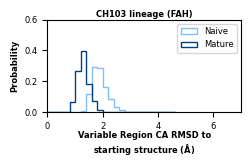

In [20]:
plt.figure(figsize=[2.5,1.2])
bins=np.arange(0,4.8,0.2)
plt.hist(naive_rmsd_values,  bins=bins,weights=naive_eq_probs,  edgecolor='#80bfff',       label='Naive', histtype='step')
plt.hist(mature_rmsd_values, bins=bins, weights=mature_eq_probs,edgecolor='#004080',       label='Mature', histtype='step')
plt.xlabel('Variable Region CA RMSD to\nstarting structure ('+r'$\mathbf{\AA}$'+')',fontsize=6, weight='bold', labelpad=0)
plt.ylabel('Probability',fontsize=6, weight='bold')
plt.title('CH103 lineage (FAH)', fontsize=6, weight='bold', pad=2)
plt.yticks(fontsize=6)
plt.xticks(fontsize=6)
plt.legend(fontsize=6)
plt.xlim(0,7)
plt.ylim(0,0.6)
plt.savefig(f"../figures/manuscript/VH_VL_RMSD_to_starting_structure_{lineage}-FAH.pdf", dpi=300, bbox_inches='tight', transparent=True)
plt.show()

# CH65

In [21]:
lineage = 'CH65'

sys_name = 'CH65_naive_VC'
VH_resis = ["1","126"]
VL_resis = ["1","108"]
naive_rmsd_values, naive_eq_probs = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1])

sys_name = 'CH65_mature_VC'
mature_rmsd_values, mature_eq_probs = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1])



[   4   21   37   54   73   89  106  117  124  134  149  165  187  211
  223  230  240  251  267  289  305  316  326  348  358  494  511  528
  552  568  592  609  621  633  640  657  664  683  698  722  739  746
  870  884  905  915  932  954  974  991  998 1022 1038 1052 1069 1083
 1107 1119 1133 1144 1163 1174 1188 1198 1219 1236 1251 1270 1281 1305
 1324 1348 1359 1371 1383 1397 1407 1423 1444 1465 1770 1794 1801 1818
 1825 1839 1853 1869 1883 1899 1910 3410 3421 3437 3456 3470 3489 3503
 3515 3526 3542 3553 3569 3581 3593 3600 3617 3631 3641 3665 3684 3698
 3708 3715 3722 3820 3836 3853 3877 3898 3915 3932 3956 3968 3975 3992
 4004 4016 4032 4051 4067 4083 4139 4151 4177 4189 4200 4207 4228 4240
 4255 4279 4299 4310 4317 4328 4342 4353 4360 4374 4388 4398 4412 4431
 4445 4464 4475 4499 4515 4530 4540 4547 4559 4574 4584 4596 4617 4638
 4811 4831 4838 4845 4852 4866 4888 4907 4921 4937]
/mnt/pure/bowmanlab/WG-shahlo/projects/Ab_dynamics/FAH-analysis-20260212/clustering/radius_15_va

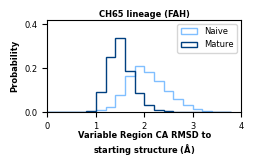

In [22]:
plt.figure(figsize=[2.5,1.2])
bins=np.arange(0,4,0.2)
plt.hist(naive_rmsd_values,  bins=bins,weights=naive_eq_probs,  edgecolor='#80bfff',       label='Naive', histtype='step')
plt.hist(mature_rmsd_values, bins=bins, weights=mature_eq_probs,edgecolor='#004080',       label='Mature', histtype='step')
plt.xlabel('Variable Region CA RMSD to\nstarting structure ('+r'$\mathbf{\AA}$'+')',fontsize=6, weight='bold', labelpad=0)
plt.ylabel('Probability',fontsize=6, weight='bold')
plt.title('CH65 lineage (FAH)', fontsize=6, weight='bold', pad=2)
plt.yticks(fontsize=6)
plt.xticks(fontsize=6)
plt.legend(fontsize=6)
plt.xlim(0,4)
plt.ylim(0,0.42)
plt.savefig(f"../figures/manuscript/VH_VL_RMSD_to_starting_structure_{lineage}-FAH.pdf", dpi=300, bbox_inches='tight', transparent=True)
plt.show()